In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

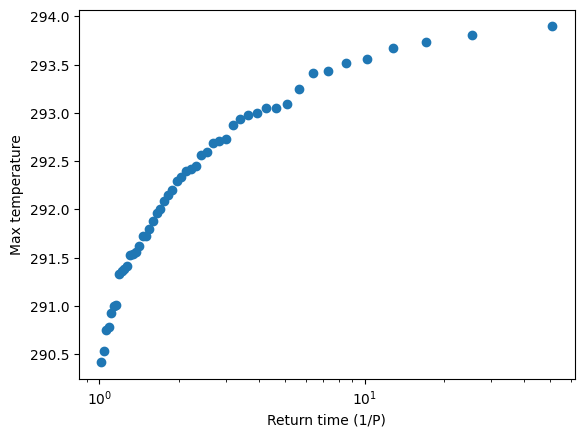

In [3]:
def ensemble_temperature(ncfile):
    ds = xr.open_dataset(ncfile)

    # pick the exact forecast time
    da = ds["mx2t"].sel(time="2021-06-29T00:00:00")

    # average over the box: 70N to 30N, 150W to 100W
    # change latitude/longitude to lat/lon if that is what your file uses
    da = da.sel(latitude=slice(70, 30), longitude=slice(-150, -100)).mean(("latitude", "longitude"))

    # one value per ensemble member
    return np.asarray(da.values).ravel()

def return_time_plot(values):
    values = np.sort(values)[::-1]  # warmest first
    n = len(values)
    p_exceed = np.arange(1, n + 1) / (n + 1)   # exceedance probability
    return_time = 1 / p_exceed
    return return_time, values

# example: one file
vals = ensemble_temperature("/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-18.nc")
rt, t = return_time_plot(vals)

plt.semilogx(rt, t, "o")
plt.xlabel("Return time (1/P)")
plt.ylabel("Max temperature")
plt.show()

38.36369836040441


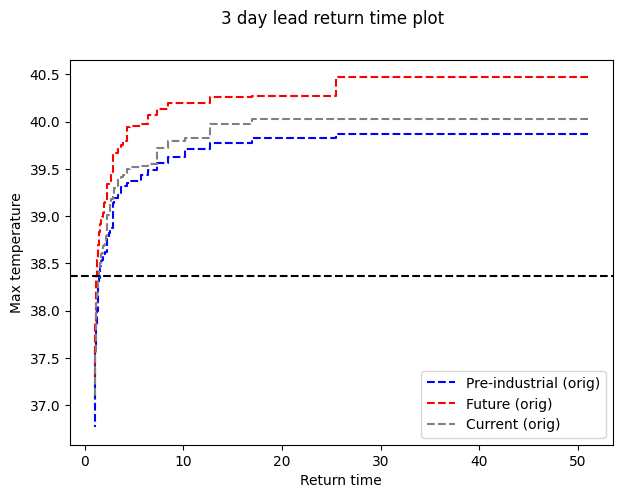

In [4]:
files = {
    "pi": {
        "file": "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc",
        "label": "Pre-industrial",
        "color": "blue",
        "marker": "o",
    },
    "incr": {
        "file": "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-26.nc",
        "label": "Future",
        "color": "red",
        "marker": "o",
    },
    "oper": {
        "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-26.nc",
        "label": "Current",
        "color": "grey",
        "marker": "o",
    },
}
    #"/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_2021-06-18T00_26d_26ens_0seed_predictions.zarr",
    #"/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-18T00_26d_26ens_0seed_predictions.zarr",
    #"/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-18T00_26d_26ens_0seed_predictions.zarr"

def ensemble_values(ncfile):
    ds = xr.open_dataset(ncfile)

    da = ds["mx2t"].sel(time=slice("2021-06-29", "2021-06-29")) - 273.15#.sel(time="2021-06-29T00:00:00") - 273.15
    if not (da.longitude < 0).any():
        da = da.assign_coords(longitude=((da.longitude + 180) % 360) - 180).sortby("longitude")
    da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))
    da = da.max("time") #temporal max, spatial mean

    da = da.mean(("latitude", "longitude")) #decided to use mean and not max as that is what nick's plot looks like it used
    return np.asarray(da.values).ravel()

def return_time(values):
    values = np.sort(values)[::-1]
    n = len(values)
    p = np.arange(1, n + 1) / (n + 1)
    rt = 1 / p
    return rt, values

plt.figure(figsize=(7, 5))

all_values = []

for info in files.values():
    vals = ensemble_values(info["file"])
    rt, temp = return_time(vals)
    #plt.semilogx(
    #    rt,
    #    temp,
    #    linestyle="None",
    #    marker=info["marker"],
    #    color=info["color"],
    #    label=info["label"],
    #)
    plt.plot(
        rt,
        temp,
        linestyle="--",
        drawstyle="steps-post",
        color=info["color"],
        label=info["label"] + " (orig)",
    )
plt.legend()

# horizontal line at the maximum temperature over the area at that time
# this uses the maximum of the ensemble-mean values from all files
era5_file = "era5_pnw025_2021.nc"
era5_ds = xr.open_dataset(era5_file, decode_timedelta=True)

era5_da = era5_ds["mx2t"].sel(time=slice("2021-06-26", "2021-06-30")) - 273.15#.sel(time="2021-06-29T00:00:00", method="nearest") - 273.15
era5_da = era5_da.sel(latitude=slice(52, 45), longitude=slice(-123, -119)) #45–52 N, 119–123 W
era5_da = era5_da.mean(dim=("latitude", "longitude"))
era5_da = era5_da.max(dim="time") #temporal max, spatial mean

yline = float(era5_da.values)
print(yline)
plt.axhline(yline, color="black", linestyle="--")

plt.xlabel("Return time")
plt.ylabel("Max temperature")
plt.legend()
plt.suptitle("3 day lead return time plot")
plt.show()

Current (26,) 0 37.370342 39.036915
38.429570206898866


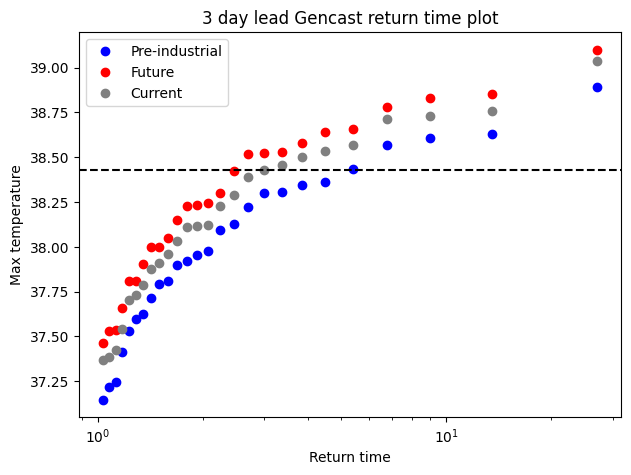

In [5]:
init_time = np.datetime64("2021-06-26T00:00:00")

files = {
    "pi": {
        "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_2021-06-26T00_10d_26ens_0seed_predictions.zarr",
        "label": "Pre-industrial",
        "color": "blue",
        "marker": "o",
    },
    "incr": {
        "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-26T00_10d_26ens_0seed_predictions.zarr",
        "label": "Future",
        "color": "red",
        "marker": "o",
    },
    "oper": {
        "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-26T00_10d_26ens_0seed_predictions.zarr",
        "label": "Current",
        "color": "grey",
        "marker": "o",
    },
}

def ensemble_values(zarrfile):
    ds = xr.open_zarr(zarrfile, consolidated=False)

    da = ds["2m_temperature"] - 273.15

    da = da.assign_coords(valid_time=("time", init_time + da["time"].values))
    da = da.swap_dims({"time": "valid_time"})
    da = da.sel(valid_time=slice("2021-06-29", "2021-06-29T23:59:59"))

    if "lat" in da.dims:
        da = da.rename({"lat": "latitude"})
    if "lon" in da.dims:
        da = da.rename({"lon": "longitude"})

    if float(da.longitude.max()) > 180:
        da = da.assign_coords(
            longitude=((da.longitude + 180) % 360) - 180
        ).sortby("longitude")

    if float(da.latitude[0]) < float(da.latitude[-1]):
        da = da.sel(latitude=slice(45, 52), longitude=slice(-123, -119))
    else:
        da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))
    da = da.mean(("latitude", "longitude"))
    da = da.max("valid_time")

    return np.asarray(da.values).ravel()

def return_time(values):
    values = np.sort(values)[::-1]
    n = len(values)
    p = np.arange(1, n + 1) / (n + 1)
    return 1 / p, values

plt.figure(figsize=(7, 5))

for info in files.values():
    vals = ensemble_values(info["file"])
    rt, temp = return_time(vals)
    plt.semilogx(
        rt,
        temp,
        linestyle="None",
        marker=info["marker"],
        color=info["color"],
        label=info["label"],
    )

plt.legend()

vals = ensemble_values(info["file"])
print(info["label"], vals.shape, np.isnan(vals).sum(), np.nanmin(vals), np.nanmax(vals))

era5_file = "era5_pnw025_2021.nc"
era5_ds = xr.open_dataset(era5_file, decode_timedelta=True)

era5_da = era5_ds["t2m"].sel(time="2021-06-29T00:00:00") - 273.15#.sel(time="2021-06-29T00:00:00", method="nearest") - 273.15
era5_da = era5_da.sel(latitude=slice(52, 45), longitude=slice(-123, -119)) #45–52 N, 119–123 W
era5_da = era5_da.mean(dim=("latitude", "longitude"))
#era5_da = era5_da.max(dim="time") #temporal max, spatial mean

yline = float(era5_da.values)
print(yline)
plt.axhline(yline, color="black", linestyle="--")

plt.xlabel("Return time")
plt.ylabel("Max temperature")
plt.title("3 day lead Gencast return time plot")
plt.show()

#takes about 2mins to run

38.4449348449707


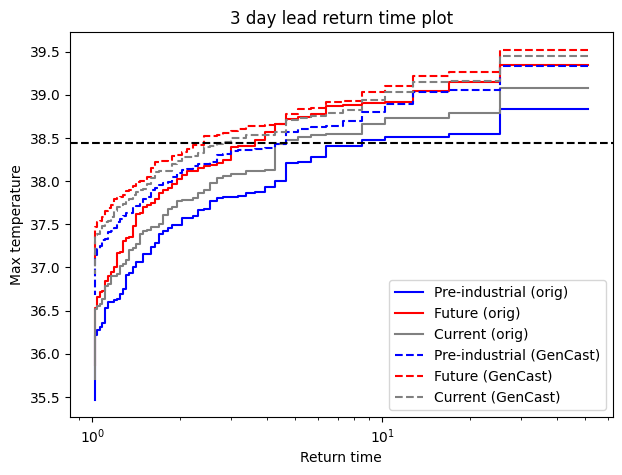

In [34]:
init_time = np.datetime64("2021-06-26T00:00:00")

orig_files = {
    "pi": {
        "file": "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc",
        "label": "Pre-industrial",
        "color": "blue",
        "marker": "o",
    },
    "incr": {
        "file": "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-26.nc",
        "label": "Future",
        "color": "red",
        "marker": "o",
    },
    "oper": {
        "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-26.nc",
        "label": "Current",
        "color": "grey",
        "marker": "o",
    },
}

gencast_files = {
    "pi": {
        "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_2021-06-26T00_10d_50ens_26-0s_24-1s_predictions.zarr",
        "label": "Pre-industrial",
        "color": "blue",
        "marker": "x",
    },
    "incr": {
        "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-26T00_10d_50ens_26-0s_24-1s_predictions.zarr",
        "label": "Future",
        "color": "red",
        "marker": "x",
    },
    "oper": {
        "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-26T00_10d_50ens_26-0s_24-1s_predictions.zarr",
        "label": "Current",
        "color": "grey",
        "marker": "x",
    },
}

def return_time(values):
    values = np.sort(values)[::-1]
    n = len(values)
    p = np.arange(1, n + 1) / (n + 1)
    return 1 / p, values

def ensemble_values_nc(ncfile):
    ds = xr.open_dataset(ncfile, decode_timedelta=True)

    da = ds["t2m"] - 273.15

    # if time exists, select the event window and take the max over time
    if "time" in da.dims:
        da = da.sel(time="2021-06-29T00:00:00")
        #da = da.max("time")

    if "latitude" in da.dims and "longitude" in da.dims:
        da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))
        da = da.mean(("latitude", "longitude"))

    return np.asarray(da.values).ravel()

def ensemble_values_zarr(zarrfile):
    ds = xr.open_zarr(zarrfile, consolidated=False)

    da = ds["2m_temperature"] - 273.15
    da = da.assign_coords(valid_time=("time", init_time + da["time"].values))
    da = da.swap_dims({"time": "valid_time"})
    da = da.sel(valid_time="2021-06-29T00:00:00")

    if "lat" in da.dims:
        da = da.rename({"lat": "latitude"})
    if "lon" in da.dims:
        da = da.rename({"lon": "longitude"})

    if float(da.longitude.max()) > 180:
        da = da.assign_coords(
            longitude=((da.longitude + 180) % 360) - 180
        ).sortby("longitude")

    if float(da.latitude[0]) < float(da.latitude[-1]):
        da = da.sel(latitude=slice(45, 52), longitude=slice(-123, -119))
    else:
        da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))

    da = da.mean(("latitude", "longitude"))
    #da = da.max("valid_time")

    return np.asarray(da.values).ravel()

plt.figure(figsize=(7, 5))

for info in orig_files.values():
    vals = ensemble_values_nc(info["file"])
    rt, temp = return_time(vals)
    #plt.semilogx(
    #    rt,
    #    temp,
    #    linestyle="None",
    #    marker=info["marker"],
    #    color=info["color"],
    #    label=info["label"] + " (orig)",
    #)
    plt.plot(
        rt,
        temp,
        drawstyle="steps-post",
        color=info["color"],
        label=info["label"] + " (orig)",
    )

plt.xscale("log")

for info in gencast_files.values():
    vals = ensemble_values_zarr(info["file"])
    rt, temp = return_time(vals)
    #plt.semilogx(
    #    rt,
    #    temp,
    #    linestyle="None",
    #    marker=info["marker"],
    #    color=info["color"],
    #    label=info["label"] + " (GenCast)",
    #)
    plt.plot(
        rt,
        temp,
        linestyle="--",
        drawstyle="steps-post",
        color=info["color"],
        label=info["label"] + " (GenCast)",
    )

era5_ds = xr.open_dataset("init_files/init_2021-06-21T00_30d.nc", decode_timedelta=True)

era5_da = era5_ds["2m_temperature"] - 273.15#.sel(time="2021-06-29T00:00:00", method="nearest") - 273.15
era5_da = era5_da.sel(lat=slice(45, 52), lon=slice(237, 241)) #45–52 N, 119–123 W
era5_da = era5_da.mean(dim=("lat", "lon"))
era5_da = era5_da.max()
print(float(era5_da.values))

plt.axhline(float(era5_da.values), color="black", linestyle="--")

plt.xlabel("Return time")
plt.ylabel("Max temperature")
plt.title("3 day lead return time plot")
plt.legend()
plt.show()

38.4449348449707
38.4449348449707


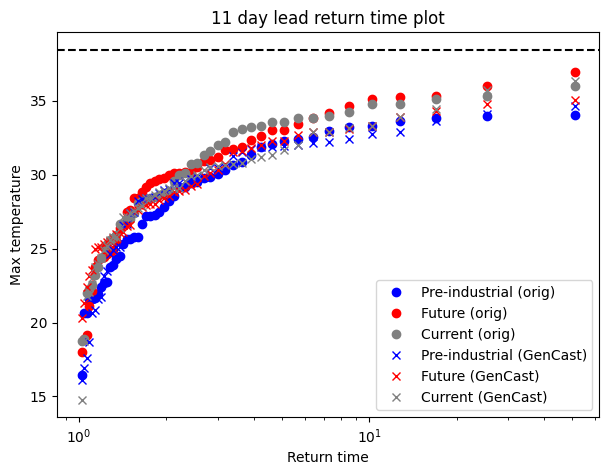

In [ ]:
init_time = np.datetime64("2021-06-18T00:00:00")
target_time = "2021-06-29T00:00:00"

orig_files = {
    "pi": {
        "file": "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-18.nc",
        "label": "Pre-industrial",
        "color": "blue",
        "marker": "o",
    },
    "incr": {
        "file": "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-18.nc",
        "label": "Future",
        "color": "red",
        "marker": "o",
    },
    "oper": {
        "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-18.nc",
        "label": "Current",
        "color": "grey",
        "marker": "o",
    },
}

gencast_files = {
    "pi": {
        "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_2021-06-18T00_26d_50ens_26-0s_24-1s_predictions.zarr",
        "label": "Pre-industrial",
        "color": "blue",
        "marker": "x",
    },
    "incr": {
        "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-18T00_26d_50ens_26-0s_24-1s_predictions.zarr",
        "label": "Future",
        "color": "red",
        "marker": "x",
    },
    "oper": {
        "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-18T00_26d_50ens_26-0s_24-1s_predictions.zarr",
        "label": "Current",
        "color": "grey",
        "marker": "x",
    },
}

def return_time(values):
    values = np.sort(values)[::-1]
    n = len(values)
    p = np.arange(1, n + 1) / (n + 1)
    return 1 / p, values


def ensemble_values_nc(ncfile):
    ds = xr.open_dataset(ncfile, decode_timedelta=True)
    da = ds["t2m"] - 273.15
    da = da.sel(time=target_time)

    if "latitude" in da.dims and "longitude" in da.dims:
        if float(da.latitude[0]) < float(da.latitude[-1]):
            da = da.sel(latitude=slice(45, 52), longitude=slice(-123, -119))
        else:
            da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))
        da = da.mean(("latitude", "longitude"))

    return np.asarray(da.values).ravel()

def ensemble_values_zarr(zarrfile, init_time):
    ds = xr.open_zarr(zarrfile, consolidated=False)
    da = ds["2m_temperature"] - 273.15

    da = da.assign_coords(valid_time=("time", init_time + da["time"].values))
    da = da.swap_dims({"time": "valid_time"})
    da = da.sel(valid_time=target_time)

    if "lat" in da.dims:
        da = da.rename({"lat": "latitude"})
    if "lon" in da.dims:
        da = da.rename({"lon": "longitude"})

    if float(da.longitude.max()) > 180:
        da = da.assign_coords(longitude=((da.longitude + 180) % 360) - 180).sortby("longitude")

    if float(da.latitude[0]) < float(da.latitude[-1]):
        da = da.sel(latitude=slice(45, 52), longitude=slice(-123, -119))
    else:
        da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))

    da = da.mean(("latitude", "longitude"))
    return np.asarray(da.values).ravel()


plt.figure(figsize=(7, 5))

for info in orig_files.values():
    vals = ensemble_values_nc(info["file"])
    rt, temp = return_time(vals)
    plt.semilogx(
        rt,
        temp,
        linestyle="None",
        marker=info["marker"],
        color=info["color"],
        label=info["label"] + " (orig)",
    )

for info in gencast_files.values():
    vals = ensemble_values_zarr(info["file"], init_time)
    rt, temp = return_time(vals)
    plt.semilogx(
        rt,
        temp,
        linestyle="None",
        marker=info["marker"],
        color=info["color"],
        label=info["label"] + " (GenCast)",
    )
    

era5_ds = xr.open_dataset("init_files/init_2021-06-21T00_30d.nc", decode_timedelta=True)

era5_da = era5_ds["2m_temperature"] - 273.15#.sel(time="2021-06-29T00:00:00", method="nearest") - 273.15
era5_da = era5_da.sel(lat=slice(45, 52), lon=slice(237, 241)) #45–52 N, 119–123 W
era5_da = era5_da.mean(dim=("lat", "lon"))
era5_da = era5_da.max()

plt.axhline(float(era5_da.values), color="black", linestyle="--")
print(float(era5_da.values))

plt.xlabel("Return time")
plt.ylabel("Max temperature")
plt.title("11 day lead return time plot")
plt.legend()
plt.show()

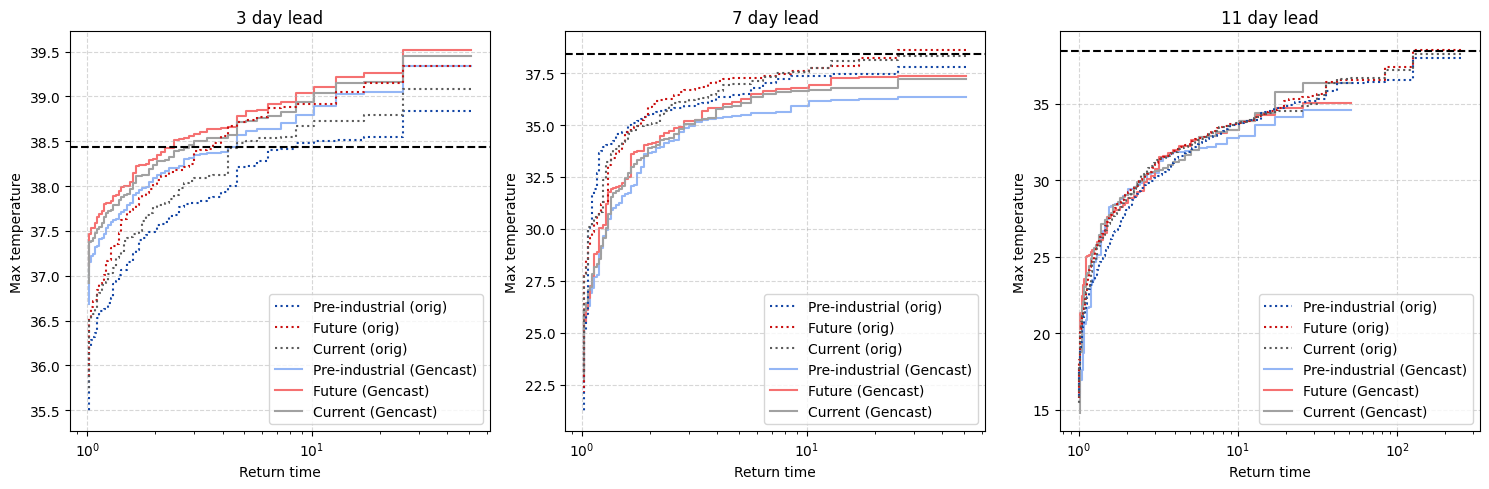

In [4]:
target_time = "2021-06-29T00:00:00"

pi_col_orig = "#0e42a3"
incr_col_orig = "#c90c0c"
oper_col_orig = "#595959"
pi_col_gencast = "#93b5f5"
incr_col_gencast = "#f56f6f"
oper_col_gencast = "#a0a0a0"
transparency = 0.99

def return_time(values):
    values = np.sort(values)[::-1]
    n = len(values)
    p = np.arange(1, n + 1) / (n + 1)
    return 1 / p, values

def ensemble_values_nc(ncfile):
    ds = xr.open_dataset(ncfile, decode_timedelta=True)
    da = ds["t2m"] - 273.15
    da = da.sel(time=target_time)

    if "latitude" in da.dims and "longitude" in da.dims:
        if float(da.latitude[0]) < float(da.latitude[-1]):
            da = da.sel(latitude=slice(45, 52), longitude=slice(-123, -119))
        else:
            da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))
        da = da.mean(("latitude", "longitude"))

    return np.asarray(da.values).ravel()

def ensemble_values_zarr(zarrfile, init_time):
    ds = xr.open_zarr(zarrfile, consolidated=False)
    da = ds["2m_temperature"] - 273.15

    da = da.assign_coords(valid_time=("time", init_time + da["time"].values))
    da = da.swap_dims({"time": "valid_time"})
    da = da.sel(valid_time=target_time)

    if "lat" in da.dims:
        da = da.rename({"lat": "latitude"})
    if "lon" in da.dims:
        da = da.rename({"lon": "longitude"})

    if float(da.longitude.max()) > 180:
        da = da.assign_coords(longitude=((da.longitude + 180) % 360) - 180).sortby("longitude")

    if float(da.latitude[0]) < float(da.latitude[-1]):
        da = da.sel(latitude=slice(45, 52), longitude=slice(-123, -119))
    else:
        da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))

    da = da.mean(("latitude", "longitude"))
    return np.asarray(da.values).ravel()

def exceedance_probability(vals, threshold):
    n = len(vals)
    nexceed = np.sum(vals >= threshold)

    if nexceed == 0:
        return f"< {1/n:.3f}", nexceed, n
    else:
        return f"{nexceed/n:.3f}", nexceed, n

def plot_panel(ax, orig_files, gencast_files, init_time, title):
    era5_ds = xr.open_dataset("era5_pnw025_2021.nc", decode_timedelta=True)
    era5_da = era5_ds["t2m"].sel(time=target_time) - 273.15
    era5_da = era5_da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))
    era5_da = era5_da.mean(("latitude", "longitude"))
    threshold = float(era5_da.values)
    
    for info in orig_files.values():
        vals = ensemble_values_nc(info["file"])

        #prob, nexceed, n = exceedance_probability(vals, threshold)
        #print(f"{title:10s} | {info['label']:15s} | Original | "
        #      f"{nexceed}/{n} exceed | P = {prob}")

        rt, temp = return_time(vals)
        #ax.semilogx(
        #    rt, temp,
        #    linestyle="None",
        #    marker="o",
        #    color=info["color"],
        #    label=info["label"] + " (orig)"
        #)
        ax.plot(
        rt,
        temp,
        linestyle=":",
        drawstyle="steps-post",
        color=info["color"],
        label=info["label"] + " (orig)",
        alpha = transparency,
        zorder = 2
        )

    for info in gencast_files.values():
        vals = ensemble_values_zarr(info["file"], init_time)

        #prob, nexceed, n = exceedance_probability(vals, threshold)
        #print(f"{title:10s} | {info['label']:15s} | GenCast | "
        #      f"{nexceed}/{n} exceed | P = {prob}")

        rt, temp = return_time(vals)
        ax.plot(
        rt,
        temp,
        linestyle="-",
        drawstyle="steps-post",
        color=info["color"],
        label=info["label"] + " (Gencast)",
        alpha = transparency,
        zorder = 1
        )

    ax.axhline(threshold, color="black", linestyle="--")

    ax.set_title(title)
    ax.set_xlabel("Return time")
    ax.set_ylabel("Max temperature")

# -----------------------------
# Put your 3 lead-time cases here
# -----------------------------
panels = [
    {
        "title": "3 day lead",
        "init_time": np.datetime64("2021-06-26T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-26.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-26.nc",
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_2021-06-26T00_10d_50ens_26-0s_24-1s_predictions.zarr",
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-26T00_10d_50ens_26-0s_24-1s_predictions.zarr",
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-26T00_10d_50ens_26-0s_24-1s_predictions.zarr",
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
    {
        "title": "7 day lead",
        "init_time": np.datetime64("2021-06-22T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-22.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-22.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-22.nc",
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_2021-06-22T00_18d_50ens_26-0s_24-1s_predictions.zarr",
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-22T00_18d_50ens_26-0s_24-1s_predictions.zarr",
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-22T00_18d_50ens_26-0s_24-1s_predictions.zarr",
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
    {
        "title": "11 day lead",
        "init_time": np.datetime64("2021-06-18T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mp_2021-06-18.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mq_2021-06-18.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/ENS/pnw025/sfc/pf/b2mr_2021-06-18.nc",
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_2021-06-18T00_26d_50ens_26-0s_24-1s_predictions.zarr",
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-18T00_26d_50ens_26-0s_24-1s_predictions.zarr",
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-18T00_26d_50ens_26-0s_24-1s_predictions.zarr",
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
]

# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)

for ax, panel in zip(axes, panels):
    plot_panel(ax, panel["orig_files"], panel["gencast_files"], panel["init_time"], panel["title"])
    ax.legend(fontsize=8)
    #ax.set_ylim(30, 40)
    #axes[0].set_ylim(35, 41)
    #axes[1].set_ylim(30, 41)
    #axes[2].set_ylim(28, 40)
    ax.legend(loc='lower right')
    ax.set_xscale("log")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [5]:
# -------------------------------------------------------
# Count members above (ERA5 - 1 std of original ensemble)
# -------------------------------------------------------

def era5_value():
    era5_ds = xr.open_dataset("era5_pnw025_2021.nc", decode_timedelta=True)
    da = era5_ds["t2m"].sel(time=target_time) - 273.15
    da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))
    da = da.mean(("latitude", "longitude"))
    return float(da.values)

era5 = era5_value()

print(f"ERA5 = {era5:.2f} °C\n")

for panel in panels:

    print("=" * 60)
    print(panel["title"])
    print("=" * 60)

    thresholds = {}

    for key, info in panel["orig_files"].items():

        vals = ensemble_values_nc(info["file"])
        std = np.std(vals)

        thresholds[key] = era5 - std

        print(
            f"{info['label']:15s} threshold = "
            f"ERA5 - σ = {thresholds[key]:.2f} °C "
            f"(σ={std:.2f})"
        )

    print()

    # ---------------------------------------------------
    # Count exceedances in ORIGINAL ensembles
    # ---------------------------------------------------
    print("Original")

    for key, info in panel["orig_files"].items():

        vals = ensemble_values_nc(info["file"])
        threshold = thresholds[key]

        n = len(vals)
        nexceed = np.sum(vals >= threshold)

        print(
            f"{info['label']:15s}: "
            f"{nexceed:2d}/{n:2d} "
            f"({100*nexceed/n:5.1f}%)"
        )

    print()

    # ---------------------------------------------------
    # Count exceedances in GenCast ensembles
    # ---------------------------------------------------
    print("GenCast")

    for key, info in panel["gencast_files"].items():

        vals = ensemble_values_zarr(info["file"], panel["init_time"])
        threshold = thresholds[key]

        n = len(vals)
        nexceed = np.sum(vals >= threshold)

        print(
            f"{info['label']:15s}: "
            f"{nexceed:2d}/{n:2d} "
            f"({100*nexceed/n:5.1f}%)"
        )

    print()

ERA5 = 38.43 °C

3 day lead


Pre-industrial  threshold = ERA5 - σ = 37.69 °C (σ=0.74)
Future          threshold = ERA5 - σ = 37.65 °C (σ=0.78)
Current         threshold = ERA5 - σ = 37.71 °C (σ=0.72)

Original
Pre-industrial : 19/50 ( 38.0%)
Future         : 33/50 ( 66.0%)
Current        : 25/50 ( 50.0%)

GenCast
Pre-industrial : 35/50 ( 70.0%)
Future         : 45/50 ( 90.0%)
Current        : 40/50 ( 80.0%)

7 day lead
Pre-industrial  threshold = ERA5 - σ = 35.25 °C (σ=3.18)
Future          threshold = ERA5 - σ = 35.08 °C (σ=3.35)
Current         threshold = ERA5 - σ = 35.35 °C (σ=3.08)

Original
Pre-industrial : 27/50 ( 54.0%)
Future         : 27/50 ( 54.0%)
Current        : 22/50 ( 44.0%)

GenCast
Pre-industrial : 13/50 ( 26.0%)
Future         : 17/50 ( 34.0%)
Current        : 12/50 ( 24.0%)

11 day lead
Pre-industrial  threshold = ERA5 - σ = 33.92 °C (σ=4.51)
Future          threshold = ERA5 - σ = 34.22 °C (σ=4.21)
Current         threshold = ERA5 - σ = 34.11 °C (σ=4.32)

Original
Pre-industrial : 20/250 (  8.0

In [11]:
import xarray as xr

ds = xr.open_dataset("/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/ENS/pnw025/sfc/pf/b2mr_2021-06-18.nc")
print(ds)

<xarray.Dataset> Size: 59GB
Dimensions:    (time: 113, number: 250, latitude: 161, longitude: 201)
Coordinates:
  * time       (time) datetime64[ns] 904B 2021-06-18 ... 2021-07-02
  * number     (number) int32 1kB 1 2 3 4 5 6 7 ... 244 245 246 247 248 249 250
  * latitude   (latitude) float32 644B 70.0 69.75 69.5 69.25 ... 30.5 30.25 30.0
  * longitude  (longitude) float32 804B -150.0 -149.8 -149.5 ... -100.2 -100.0
Data variables:
    swvl1      (time, number, latitude, longitude) float64 7GB ...
    tcwv       (time, number, latitude, longitude) float64 7GB ...
    tcc        (time, number, latitude, longitude) float64 7GB ...
    t2m        (time, number, latitude, longitude) float64 7GB ...
    e          (time, number, latitude, longitude) float64 7GB ...
    mx2t       (time, number, latitude, longitude) float64 7GB ...
    mn2t       (time, number, latitude, longitude) float64 7GB ...
    tp         (time, number, latitude, longitude) float64 7GB ...
Attributes:
    Conventions: